# Assessing method performance in cases of model mis-specification
These experiments all use simulated data to evaluate the robustness to mis-specification 
of the Bernoulli model and the MLE methodology of estimating gene prevalence. The 
mis-specification includes violations of model assumptions of data independence and 
distribution, as well as errors in estimating parameters that are used as inputs to the 
MLE method.

List of experiments:
- Errors in lambda (genome completeness parameter)
- Gene detection bias 
    - Differences in gene copy number (specific case of gene detection bias)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from gene_prevalence import BernoulliPrevalenceModel
from gene_prevalence.simulations import build_observed_data_matrix, \
    build_presence_absence_matrix

# instatiate random number generator with fixed seed for reproducibility
rng = np.random.default_rng(seed=918)

# set confidence interval alpha level
ci_alpha = 0.05


In [2]:
# set aesthetic parameters

line_color = '#0F0A0A'    # dark

neutral_color = '#E0E0E0'

# thursday
accent_colors = ['#9B5DE5', '#FFAC69', '#00C9AE', '#FD3F92', '#0F0A0A', 
                 '#959AB1', '#FFDB66', '#63B9FF','#FFB1CA', '#4F1DD7']

style = {'axes.edgecolor': line_color,
         'axes.labelcolor': line_color,
         'text.color': line_color,
         'xtick.color': line_color,
         'ytick.color': line_color,
         'font.family': 'Helvetica',
         'font.Helvetica': ['Helvetica']}

palette = sns.color_palette(accent_colors)

sns.set_context('talk', rc={'lines.linewidth': 2})
sns.set_palette(palette)
sns.set_style('ticks', style)

plt.rcParams['legend.frameon'] = False
plt.rcParams['axes.spines.left'] = True
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.bottom'] = True
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['patch.linewidth'] = 0
plt.rcParams['patch.edgecolor'] = 'none'
plt.rcParams['savefig.dpi'] = 300

## Experiment 1: Errors in Lambda
Performance of model when there are errors in the genome completeness parameter estimate. 

Genome completeness is estimated in the JGI pipeline using [CheckM2](https://github.com/chklovski/CheckM2) 
(see [documentation](https://sites.google.com/lbl.gov/imghelp/home/img-and-gold-terms)). 
CheckM2 uses machine learning models (gradient boosteddecision tree and neural networks) 
to predict the completeness of a prokaryotic genome independent of its lineage, based on 
KEGG annotations (see [Chlovski et al., 2023](https://www.nature.com/articles/s41592-023-01940-w)). 
Other common approaches, such as CheckM1 and [BUSCO](https://busco.ezlab.org/) use curated 
sets of single copy marker genes (SCGs) shared among all members of particular
evolutionary lineages, and evaluate the completeness of new genomes based on how many of 
these marker genes are found to be present. While CheckM2 has been demonstrated to be more
accurate than the SCG approach, both are estimates based on the genes detected in a genome
and are prone to error. We thus evaluated the robustness of our methodology to errors in
estimating the completeness of the genome.

The latest version of BUSCO (v6.1.0) has a gene set specific to Prochlorococcus that 
consists of 1128 single copy marker genes.

In [3]:
# build simulated data that matches model assumptions 
# (same as in 2-method-comparison-simulations.ipynb)

n_genomes = 1000
n_genes = 12000

# generate true pi values for all genes in the pangenome, using a beta distribution
pi_vector_true = np.clip(rng.beta(a=0.2, b=0.5, size=n_genes) * 1.06, 0, 1)

# build a presence-absence matrix based on the true pi values
presence_absence_matrix = build_presence_absence_matrix(
    pi_vector=pi_vector_true, 
    n_genomes=n_genomes, 
    n_genes=n_genes,
    rng=rng
    )
print("Mean genes per genome:", round(presence_absence_matrix.sum(axis=1).mean()))

# generate completeness values for each genome, with a subset being complete
completeness_vector = pd.Series(
    np.clip(rng.uniform(low=0.05, high=1.1, size=n_genomes), 0, 1), 
    index=presence_absence_matrix.index
    )
print("N complete simulated genomes:", (completeness_vector == 1).sum())
print("N incomplete simulated genomes:", (completeness_vector < 1).sum())

# build an observed data matrix by simulating the observation process with no 
# gene-specific biases and not enforcing completeness (i.e. simulating each gene 
# observation as an independent Bernoulli trial)
observed_data_matrix, observation_mask = build_observed_data_matrix(
    presence_absence_matrix=presence_absence_matrix,
    completeness_levels=completeness_vector,
    rng=rng, 
    return_observation_mask=True
    )

observed_data_matrix

Mean genes per genome: 3614
N complete simulated genomes: 93
N incomplete simulated genomes: 907


,sim_gene_0,sim_gene_1,sim_gene_2,sim_gene_3,sim_gene_4,sim_gene_5,sim_gene_6,sim_gene_7,sim_gene_8,sim_gene_9,...,sim_gene_11990,sim_gene_11991,sim_gene_11992,sim_gene_11993,sim_gene_11994,sim_gene_11995,sim_gene_11996,sim_gene_11997,sim_gene_11998,sim_gene_11999
sim_genome_0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
sim_genome_1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
sim_genome_2,0,1,0,0,0,1,0,0,1,0,...,0,1,1,0,0,0,1,0,0,0
sim_genome_3,0,1,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
sim_genome_4,0,0,0,0,1,1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
sim_genome_995,0,0,0,1,1,1,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
sim_genome_996,1,1,0,1,0,1,0,0,1,0,...,0,0,1,1,0,0,0,0,0,0
sim_genome_997,0,1,0,0,1,1,0,0,1,0,...,0,0,0,1,0,0,0,0,0,0
sim_genome_998,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [4]:
# subset all data to only observed genes

# identify observed genes
observed_genes = (observed_data_matrix.sum(axis=0) > 0)
observed_genes = observed_genes[observed_genes].index

# true pie values for observed genes
true_pi_values = pd.Series(pi_vector_true, index=presence_absence_matrix.columns)
true_pi_values = true_pi_values[observed_genes]

# observed data matrix for observed genes
observed_data_matrix = observed_data_matrix[observed_genes]

# assign genes to pangenome categories based on their true pi values
category_definitions = {
    'overall': true_pi_values.index, 
    'core': true_pi_values[true_pi_values == 1.0].index, 
    'extended_core': true_pi_values[true_pi_values >= 0.9].index,
    'flexible': true_pi_values[true_pi_values < 1.0].index,
    'shell': true_pi_values[(true_pi_values > 0.15) & (true_pi_values < 0.9)].index,
    'cloud': true_pi_values[true_pi_values <= 0.15].index
}

# print number of genes in each category
for category, genes in category_definitions.items():
    print(f"{category}: {len(genes)} genes")


overall: 9544 genes
core: 948 genes
extended_core: 1556 genes
flexible: 8596 genes
shell: 3947 genes
cloud: 4041 genes


In [5]:
# generate noisy completeness estimates by simulating the process of sampling marker
# genes as a binomial trial, where the random variable is the number of marker genes observed, 
# the number of trials is the total number of marker genes, and the probability of success 
# is the true completeness level for that genome

# set a number of different marker genes to evaluate
n_marker_genes_options = [1, 5, 10, 50, 100, 500, 1000, 1128, 2000, 3000]

# build pandas dataframe of simulated completeness estimates for each genome and each number of marker genes
noisy_lambdas_df = pd.DataFrame(
    index=presence_absence_matrix.index, 
    columns=['true_lambda'] + [f"n={n}" for n in n_marker_genes_options])
noisy_lambdas_df['true_lambda'] = completeness_vector

# generate noisy completeness estimates for each number of marker genes
for n_marker_genes in n_marker_genes_options:
    # simulate number of marker genes observed for each genome
    n_marker_genes_observed = rng.binomial(
        n=n_marker_genes, 
        p=completeness_vector
        )
    
    # calculate noisy completeness estimates as the proportion of marker genes observed
    noisy_completeness_estimates = n_marker_genes_observed / n_marker_genes
    
    # add noisy completeness estimates to dataframe
    noisy_lambdas_df[f"n={n_marker_genes}"] = noisy_completeness_estimates

noisy_lambdas_df

,true_lambda,n=1,n=5,n=10,n=50,n=100,n=500,n=1000,n=1128,n=2000,n=3000
sim_genome_0,0.115176,1.0,0.0,0.2,0.06,0.10,0.112,0.110,0.103723,0.1285,0.119333
sim_genome_1,0.142442,0.0,0.0,0.1,0.20,0.14,0.148,0.139,0.123227,0.1365,0.145000
sim_genome_2,0.448693,0.0,0.6,0.1,0.60,0.52,0.444,0.443,0.429078,0.4325,0.441667
sim_genome_3,0.209545,0.0,0.2,0.2,0.20,0.18,0.184,0.204,0.207447,0.2080,0.200333
sim_genome_4,0.412330,0.0,0.4,0.4,0.40,0.40,0.400,0.427,0.398050,0.4090,0.403333
...,...,...,...,...,...,...,...,...,...,...,...
sim_genome_995,0.691049,1.0,0.2,0.6,0.70,0.70,0.686,0.692,0.683511,0.6990,0.688000
sim_genome_996,0.772338,1.0,0.8,0.8,0.72,0.73,0.766,0.779,0.758865,0.7815,0.772333
sim_genome_997,0.952499,1.0,1.0,0.8,0.94,0.98,0.970,0.958,0.947695,0.9460,0.957333
sim_genome_998,0.175930,0.0,0.4,0.0,0.14,0.25,0.202,0.169,0.171986,0.1705,0.169667


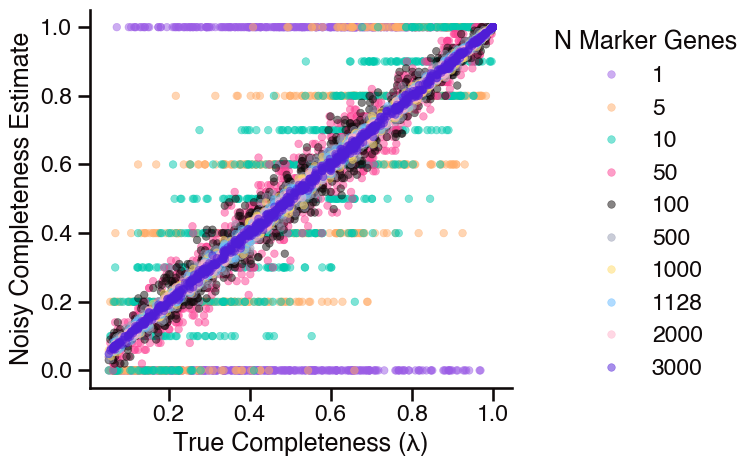

In [6]:
# plot scatterplot of true completeness vs. noisy completeness estimates, colored by number of marker genes

# reshape dataframe to long format for plotting
plot_df = noisy_lambdas_df.melt(id_vars='true_lambda', var_name='n_marker_genes', value_name='noisy_lambda')
plot_df['n_marker_genes'] = plot_df['n_marker_genes'].str.replace('n=', '').astype(int)

# build scatterplot
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=plot_df, 
    x='true_lambda', 
    y='noisy_lambda', 
    hue='n_marker_genes', 
    palette=palette,
    alpha=0.5, 
    s=30, 
    edgecolor=None
)
plt.xlabel('True Completeness (λ)')
plt.ylabel('Noisy Completeness Estimate')
plt.legend(title='N Marker Genes', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [7]:
# evaluate MSE and coverage of confidence intervals for each number of marker genes, 
# using the simulated prevalence as the ground truth and the noisy completeness 
# estimates as the input to the model

results = []
for n_marker_genes in n_marker_genes_options:
    # get noisy completeness estimates for this number of marker genes
    noisy_completeness_estimates = noisy_lambdas_df[f"n={n_marker_genes}"]
    
    # fit prevalence model using noisy completeness estimates as input
    model = BernoulliPrevalenceModel(
        data=observed_data_matrix, 
        lambdas=noisy_completeness_estimates, 
        )
    fit = model.fit(
        estimator="mle",
        interval_method="likelihood_ratio",
        alpha=ci_alpha,
        clip=True,
    )
    pi_hat = fit.prevalence
    ci_lower, ci_upper = fit.confidence_interval()  # confidence interval bounds

    # evaluate MSE and coverage for each subset of genes
    for category, genes in category_definitions.items():

        # calculate MSE of estimated pi values compared to true pi values for this subset of genes
        mse = np.mean((pi_hat[genes] - true_pi_values[genes]) ** 2)

        # calculate confidence interval coverage
        # (proportion of true pi values that fall within the intervals) for this subset of genes
        coverage = np.mean((true_pi_values[genes] >= ci_lower[genes]) & (true_pi_values[genes] <= ci_upper[genes]))

        # store results in a list
        results.append({
            'n_marker_genes': n_marker_genes,
            'category': category,
            'mse': mse,
            'coverage': coverage,
            'se_coverage': np.sqrt(coverage * (1 - coverage) / len(genes))  # standard error of coverage estimate
        })

# convert results to a pandas dataframe
lambda_test_df = pd.DataFrame(results)
lambda_test_df


,n_marker_genes,category,mse,coverage,se_coverage
0,1,overall,0.022529,0.301551,0.004698
1,1,core,0.080181,0.000000,0.000000
2,1,extended_core,0.077468,0.000000,0.000000
3,1,flexible,0.016171,0.334807,0.005090
4,1,shell,0.023617,0.012161,0.001745
5,1,cloud,0.000311,0.700322,0.007207
6,5,overall,0.001680,0.683256,0.004762
7,5,core,0.006675,0.000000,0.000000
8,5,extended_core,0.006284,0.000000,0.000000
9,5,flexible,0.001129,0.758609,0.004616


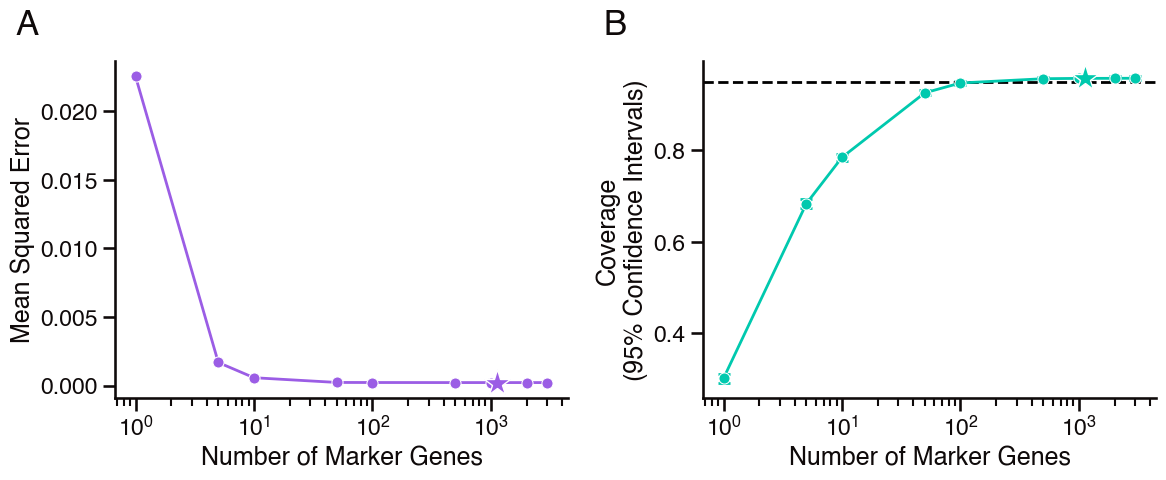

In [8]:
# plot MSE and coverage for overall category as a function of number of marker genes

# filter results to overall category
overall_df = lambda_test_df[lambda_test_df['category'] == 'overall']

# make two subplots: one for MSE and one for coverage
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))

# annotation specs
annotation_kwargs = dict(
    xy=(-0.22, 1.08),
    xycoords='axes fraction',
    fontsize=25,
    fontweight='bold'
)

# plot A: MSE as a function of number of marker genes
sns.lineplot(
    data=overall_df, 
    x='n_marker_genes', 
    y='mse', 
    color=palette[0],
    marker='o', 
    ms=8, 
    ax=axes[0]
)
axes[0].set_xscale('log')
axes[0].set_xlabel('Number of Marker Genes')
axes[0].set_ylabel('Mean Squared Error')
# mark the MSE for 1128 marker genes with a star
mse_1128 = overall_df[overall_df['n_marker_genes'] == 1128]['mse'].values[0]
axes[0].plot(1128, mse_1128, marker='*', color=palette[0], markersize=20, markeredgecolor='white')
# add annotation for subplot A
axes[0].annotate("A", **annotation_kwargs)

# plot B: coverage as a function of number of marker genes
sns.lineplot(
    data=overall_df, 
    x='n_marker_genes', 
    y='coverage', 
    color=palette[2],
    marker='o', 
    ms=8,
    ax=axes[1]
)
# add error bars for +/- 2 standard errors of the coverage estimate
axes[1].errorbar(
    x=overall_df['n_marker_genes'],
    y=overall_df['coverage'],
    yerr=(overall_df['se_coverage'] * 2),  # 2 standard errors for approximate 95% confidence interval
    fmt='none',
    ecolor=palette[2],
    elinewidth=2,
    capsize=4,
    capthick=2, 
    zorder=0
)
axes[1].set_xscale('log')
axes[1].set_xlabel('Number of Marker Genes')
axes[1].set_ylabel(f'Coverage\n({(1 - ci_alpha):.0%} Confidence Intervals)')
# add horizontal line at the nominal coverage level as reference
axes[1].axhline(1 - ci_alpha, color='black', linestyle='--', zorder=1)
# mark the coverage for 1128 marker genes with a star
coverage_1128 = overall_df[overall_df['n_marker_genes'] == 1128]['coverage'].values[0]
axes[1].plot(1128, coverage_1128, marker='*', color=palette[2], markersize=20, markeredgecolor='white')
# add annotation for subplot B
axes[1].annotate("B", **annotation_kwargs)

# show and save the figure
plt.tight_layout()
# plt.savefig("marker_gene_simulation_results.png", dpi=300, bbox_inches='tight')
plt.show()

## Experiment 2: Biases in gene detection


In [9]:
# build new observed data matrix where the observation process is simulated with gene-specific biases,
# such that some genes are more likely to be observed than others, even at the same completeness level

# set a number of different beta distribution parameters to evaluate
beta_values = [1, 0.3, 0.1, 0.03, 0.01, 0.003, 0.001, 0.0003, 0.0001, None]
alpha = 1

# iterate over different beta distribution parameters and evaluate model performance for each one
biases_df = pd.DataFrame(index=presence_absence_matrix.columns)
pi_predictions_df = pd.DataFrame(index=presence_absence_matrix.columns)
pi_predictions_df['true_pi'] = pi_vector_true
results = []
for beta in beta_values:
    if beta is None:
        # if beta is None, set all detection biases to 1 (i.e. no bias)
        detection_biases = np.ones(n_genes)
        label = "No Bias"
        print("No bias scenario")
    else:
        # set gene-specific detection biases
        detection_biases = rng.beta(a=alpha, b=beta, size=n_genes)
        label = f"Beta({alpha}, {beta})"
        print(f"Beta distribution parameters: alpha={alpha}, beta={beta}")
    biases_df[label] = detection_biases

    # use same underlying presence-absence matrix and completeness levels as before, 
    # but simulate the observation process with gene-specific biases by assigning each gene a random bias factor that modifies the probability of observing that gene in each genome
    observed_data_matrix = build_observed_data_matrix(
        presence_absence_matrix=presence_absence_matrix,
        completeness_levels=completeness_vector,
        rng=rng, 
        gene_biases=detection_biases,
        return_observation_mask=False
        )

    # subset observed data matrix to only observed genes
    observed_genes = (observed_data_matrix.sum(axis=0) > 0)
    observed_genes = observed_genes[observed_genes].index
    observed_data_matrix = observed_data_matrix[observed_genes]

    # set true pi values for observed genes
    true_pi_values = pd.Series(pi_vector_true, index=presence_absence_matrix.columns)
    true_pi_values = true_pi_values[observed_genes]

    # re-assign genes to pangenome categories based on their true pi values
    category_definitions = {
        'overall': true_pi_values.index, 
        'core': true_pi_values[true_pi_values == 1.0].index, 
        'extended_core': true_pi_values[true_pi_values >= 0.9].index,
        'flexible': true_pi_values[true_pi_values < 1.0].index,
        'shell': true_pi_values[(true_pi_values > 0.15) & (true_pi_values < 0.9)].index,
        'cloud': true_pi_values[true_pi_values <= 0.15].index
    }

    # fit prevalence model using true completeness levels as input
    model = BernoulliPrevalenceModel(
        data=observed_data_matrix, 
        lambdas=completeness_vector, 
        )
    fit = model.fit(
        estimator="mle",
        interval_method="likelihood_ratio",
        alpha=ci_alpha,
        clip=True,
    )
    pi_hat = fit.prevalence
    ci_lower, ci_upper = fit.confidence_interval()  # confidence interval bounds
    pi_predictions_df[label] = pi_hat

    # evaluate MSE and coverage for each subset of genes
    for category, genes in category_definitions.items():

        # calculate MSE of estimated pi values compared to true pi values for this subset of genes
        mse = np.mean((pi_hat[genes] - true_pi_values[genes]) ** 2)

        # calculate confidence interval coverage
        # (proportion of true pi values that fall within the intervals) for this subset of genes
        coverage = np.mean((true_pi_values[genes] >= ci_lower[genes]) & (true_pi_values[genes] <= ci_upper[genes]))

        # store results in a list
        results.append({
            'scenario': label,
            'alpha': alpha,
            'beta': None if alpha is None else beta,
            'category': category,
            'mse': mse,
            'coverage': coverage,
            'se_coverage': np.sqrt(coverage * (1 - coverage) / len(genes))  # standard error of coverage estimate
        })

# convert results to a pandas dataframe
bias_test_df = pd.DataFrame(results)
bias_test_df


Beta distribution parameters: alpha=1, beta=1
Beta distribution parameters: alpha=1, beta=0.3
Beta distribution parameters: alpha=1, beta=0.1
Beta distribution parameters: alpha=1, beta=0.03
Beta distribution parameters: alpha=1, beta=0.01
Beta distribution parameters: alpha=1, beta=0.003
Beta distribution parameters: alpha=1, beta=0.001
Beta distribution parameters: alpha=1, beta=0.0003
Beta distribution parameters: alpha=1, beta=0.0001
No bias scenario


,scenario,alpha,beta,category,mse,coverage,se_coverage
0,"Beta(1, 1)",1,1.0000,overall,0.004966,0.597238,0.005016
1,"Beta(1, 1)",1,1.0000,core,0.010971,0.727848,0.014455
2,"Beta(1, 1)",1,1.0000,extended_core,0.011635,0.557841,0.012590
3,"Beta(1, 1)",1,1.0000,flexible,0.004305,0.582859,0.005314
4,"Beta(1, 1)",1,1.0000,shell,0.007259,0.349633,0.007590
5,"Beta(1, 1)",1,1.0000,cloud,0.000176,0.853304,0.005555
6,"Beta(1, 0.3)",1,0.3000,overall,0.007407,0.610278,0.004994
7,"Beta(1, 0.3)",1,0.3000,core,0.019520,0.767932,0.013711
8,"Beta(1, 0.3)",1,0.3000,extended_core,0.020432,0.570694,0.012548
9,"Beta(1, 0.3)",1,0.3000,flexible,0.006069,0.592873,0.005302


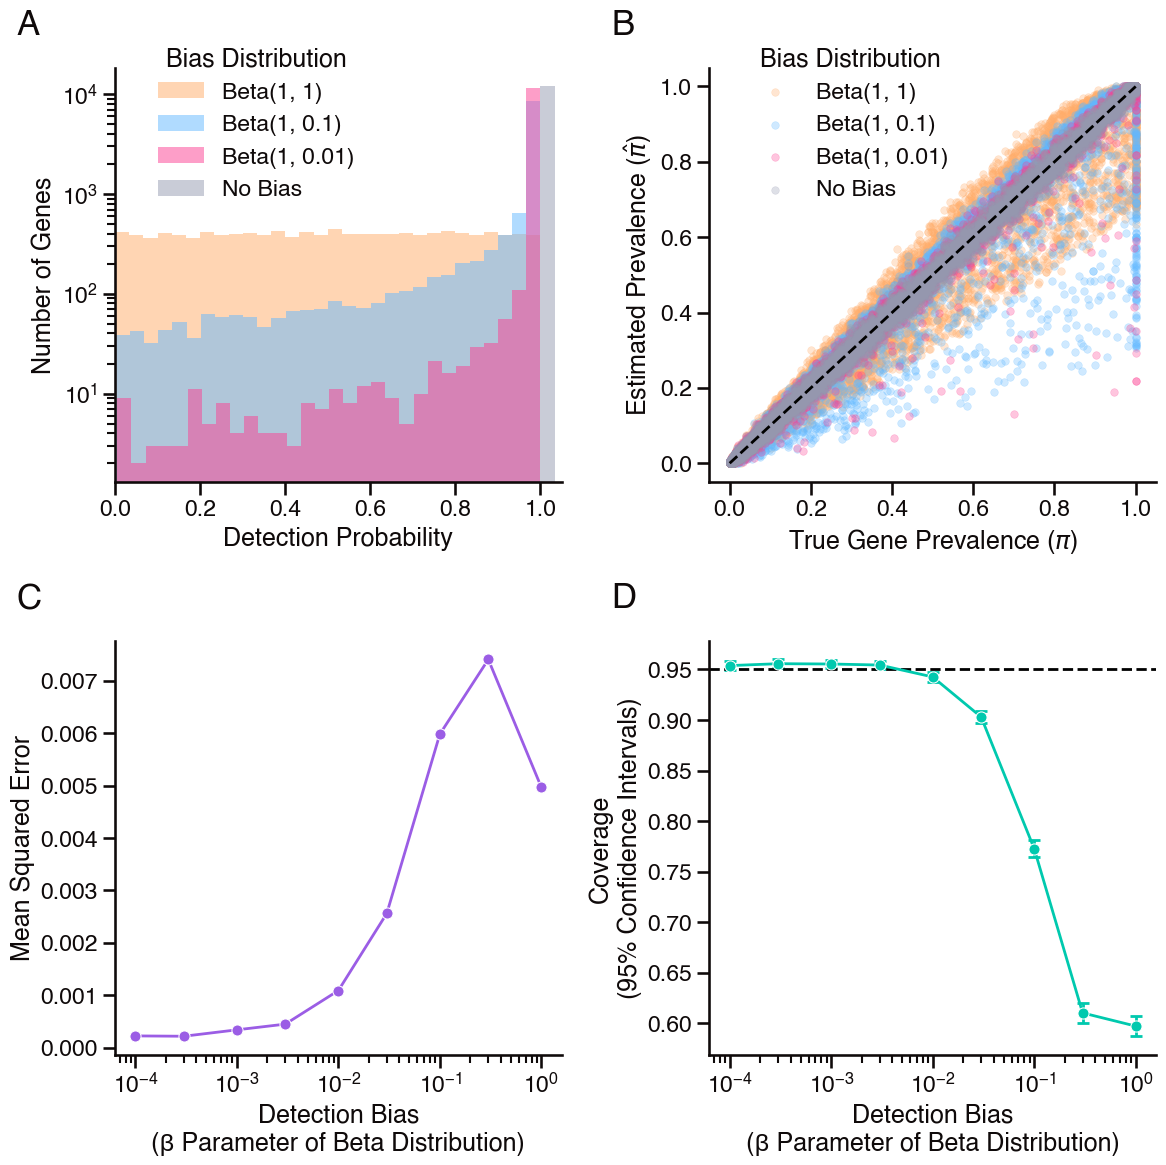

In [10]:
# build multi-panel figure showing results from bias test

# build figure with 2 rows and 2 columns of subplots
fig, axes = plt.subplots(2, 2, figsize=(12, 12))

# build plot A: overlay of gene detection bias distributions for different beta distribution parameters
subset = ['Beta(1, 1)', 'Beta(1, 0.1)', 'Beta(1, 0.01)', 'No Bias']
color_mapping = dict(zip(subset, [palette[i] for i in [1, 7, 3, 5][:len(subset)]]))
for i, label in enumerate(subset):
    sns.histplot(
        biases_df[label], 
        label=label, 
        color=color_mapping[label], 
        alpha=0.5, 
        bins=30,
        ax=axes[0, 0]
    )
axes[0, 0].set_xlabel("Detection Probability")
axes[0, 0].set_ylabel("Number of Genes")
axes[0, 0].set_xlim(0, 1.05)
# axes[0, 0].set_ylim(0, 10000)
axes[0, 0].set_yscale('log')
axes[0, 0].legend(title="Bias Distribution", bbox_to_anchor=(0.05, 1.1), loc='upper left')
axes[0, 0].annotate("A", **annotation_kwargs)

# plot B: scatterplots of true pi values vs. estimated pi values for each beta distribution parameter
for i, label in enumerate(subset):
    sns.scatterplot(
        x=pi_predictions_df['true_pi'], 
        y=pi_predictions_df[label], 
        label=label,
        color=color_mapping[label], 
        alpha=0.3, 
        s=30, 
        edgecolor=None,
        ax=axes[0, 1]
    )
# add diagonal line for reference
axes[0, 1].plot([0, 1], [0, 1], color='black', linestyle='--', zorder=1)
axes[0, 1].set_xlabel(r"True Gene Prevalence ($\pi$)")
axes[0, 1].set_ylabel(r"Estimated Prevalence ($\hat{\pi}$)")
axes[0, 1].legend(title="Bias Distribution", bbox_to_anchor=(0.05, 1.1), loc='upper left')
axes[0, 1].annotate("B", **annotation_kwargs)

# plot C: MSE of estimated pi values compared to true pi values for each beta distribution parameter (overall category)
overall_bias_df = bias_test_df[bias_test_df['category'] == 'overall']
sns.lineplot(
    data=overall_bias_df, 
    x='beta', 
    y='mse', 
    color=palette[0], 
    ax=axes[1, 0], 
    marker='o', 
    ms=8
)
axes[1, 0].set_xlabel("Detection Bias\n(β Parameter of Beta Distribution)")
axes[1, 0].set_xscale('log')
axes[1, 0].set_ylabel("Mean Squared Error")
axes[1, 0].annotate("C", **annotation_kwargs)

# plot D: coverage of confidence intervals for each beta distribution parameter (overall category)
sns.lineplot(
    data=overall_bias_df, 
    x='beta', 
    y='coverage', 
    color=palette[2], 
    ax=axes[1, 1], 
    marker='o', 
    ms=8
)
# add error bars for +/- 2 standard errors of the coverage estimate
axes[1, 1].errorbar(
    x=overall_bias_df['beta'],
    y=overall_bias_df['coverage'],
    yerr=(overall_bias_df['se_coverage'] * 2),  # 2 standard errors for approximate 95% confidence interval
    fmt='none',
    ecolor=palette[2],
    elinewidth=2,
    capsize=4,
    capthick=2, 
    zorder=0
)
axes[1, 1].set_xlabel("Detection Bias\n(β Parameter of Beta Distribution)")
axes[1, 1].set_xscale('log')
axes[1, 1].set_ylabel(f"Coverage\n({(1 - ci_alpha):.0%} Confidence Intervals)")
axes[1, 1].axhline(1 - ci_alpha, color='black', linestyle='--', zorder=1)
axes[1, 1].annotate("D", **annotation_kwargs)   

# show and save the figure
plt.tight_layout()
# plt.savefig("bias_simulation_results.png", dpi=300, bbox_inches='tight')
plt.show()

## Experiment 3: Multicopy genes
Simulate biases in gene detection as a result of multicopy genes

In [11]:
# simulate different copy numbers for different genes, resulting in different levels
# of detection bias proportional to copy number

# set of different lambda values to generate poisson counts for each gene
poisson_lambdas = [None, 0.001, 0.01, 0.023, 0.05, 0.1, 0.2, 0.5, 1]

# iterate over different lambda values
counts_df = pd.DataFrame(index=presence_absence_matrix.columns)
pi_predictions_df = pd.DataFrame(index=presence_absence_matrix.columns)
pi_predictions_df['true_pi'] = pi_vector_true
results = []
for lamb in poisson_lambdas:
    if lamb is None:
        # if lambda is None, set all gene counts to 1 (i.e. no bias)
        gene_counts = np.ones(n_genes)
        label = "No Bias"
        print("No bias scenario")
    else:
        # set gene-specific detection biases
        gene_counts = rng.poisson(lam=lamb, size=n_genes) + 1  # add 1 to ensure all genes have at least 1 copy
        label = f"Pois({lamb})"
        print(f"Poisson distribution parameter: lambda={lamb}")
    counts_df[label] = gene_counts

    # use same underlying presence-absence matrix and completeness levels as before, 
    # but simulate observation biases that reflect gene copy number 
    observed_data_matrix = build_observed_data_matrix(
        presence_absence_matrix=presence_absence_matrix,
        completeness_levels=completeness_vector,
        rng=rng, 
        gene_biases=gene_counts / gene_counts.max(),  # convert gene counts to probabilities by normalizing to the maximum count
        return_observation_mask=False, 
        enforce_completeness=True
        )

    # subset observed data matrix to only observed genes
    observed_genes = (observed_data_matrix.sum(axis=0) > 0)
    observed_genes = observed_genes[observed_genes].index
    observed_data_matrix = observed_data_matrix[observed_genes]

    # set true pi values for observed genes
    true_pi_values = pd.Series(pi_vector_true, index=presence_absence_matrix.columns)
    true_pi_values = true_pi_values[observed_genes]

    # re-assign genes to pangenome categories based on their true pi values
    category_definitions = {
        'overall': true_pi_values.index, 
        'core': true_pi_values[true_pi_values == 1.0].index, 
        'extended_core': true_pi_values[true_pi_values >= 0.9].index,
        'flexible': true_pi_values[true_pi_values < 1.0].index,
        'shell': true_pi_values[(true_pi_values > 0.15) & (true_pi_values < 0.9)].index,
        'cloud': true_pi_values[true_pi_values <= 0.15].index
    }

    # fit prevalence model using true completeness levels as input
    model = BernoulliPrevalenceModel(
        data=observed_data_matrix, 
        lambdas=completeness_vector, 
        )
    fit = model.fit(
        estimator="mle",
        interval_method="likelihood_ratio",
        alpha=ci_alpha,
        clip=True,
    )
    pi_hat = fit.prevalence
    ci_lower, ci_upper = fit.confidence_interval()  # confidence interval bounds
    pi_predictions_df[label] = pi_hat

    # evaluate MSE and coverage for each subset of genes
    for category, genes in category_definitions.items():

        # calculate MSE of estimated pi values compared to true pi values for this subset of genes
        mse = np.mean((pi_hat[genes] - true_pi_values[genes]) ** 2)

        # calculate confidence interval coverage
        # (proportion of true pi values that fall within the intervals) for this subset of genes
        coverage = np.mean((true_pi_values[genes] >= ci_lower[genes]) & (true_pi_values[genes] <= ci_upper[genes]))

        # store results in a list
        results.append({
            'label': label,
            'lambda': lamb,
            'mean_copy_number': gene_counts.mean(),
            'mean_cn_minus_one': gene_counts.mean() - 1,
            'category': category,
            'mse': mse,
            'coverage': coverage, 
            'se_coverage': np.sqrt(coverage * (1 - coverage) / len(genes))  # standard error of coverage estimate
        })

# convert results to a pandas dataframe
cn_test_df = pd.DataFrame(results)
cn_test_df
    
    

No bias scenario
Poisson distribution parameter: lambda=0.001
Poisson distribution parameter: lambda=0.01
Poisson distribution parameter: lambda=0.023
Poisson distribution parameter: lambda=0.05
Poisson distribution parameter: lambda=0.1
Poisson distribution parameter: lambda=0.2
Poisson distribution parameter: lambda=0.5
Poisson distribution parameter: lambda=1


,label,lambda,mean_copy_number,mean_cn_minus_one,category,mse,coverage,se_coverage
0,No Bias,NaN,1.000000,0.000000,overall,0.000224,0.953817,0.002148
1,No Bias,NaN,1.000000,0.000000,core,0.000005,1.000000,0.000000
2,No Bias,NaN,1.000000,0.000000,extended_core,0.000088,0.974936,0.003963
3,No Bias,NaN,1.000000,0.000000,flexible,0.000249,0.948727,0.002378
4,No Bias,NaN,1.000000,0.000000,shell,0.000443,0.946035,0.003596
5,No Bias,NaN,1.000000,0.000000,cloud,0.000064,0.953287,0.003318
6,Pois(0.001),0.001,1.001167,0.001167,overall,0.000226,0.954888,0.002123
7,Pois(0.001),0.001,1.001167,0.001167,core,0.000004,1.000000,0.000000
8,Pois(0.001),0.001,1.001167,0.001167,extended_core,0.000080,0.980077,0.003542
9,Pois(0.001),0.001,1.001167,0.001167,flexible,0.000251,0.949919,0.002351


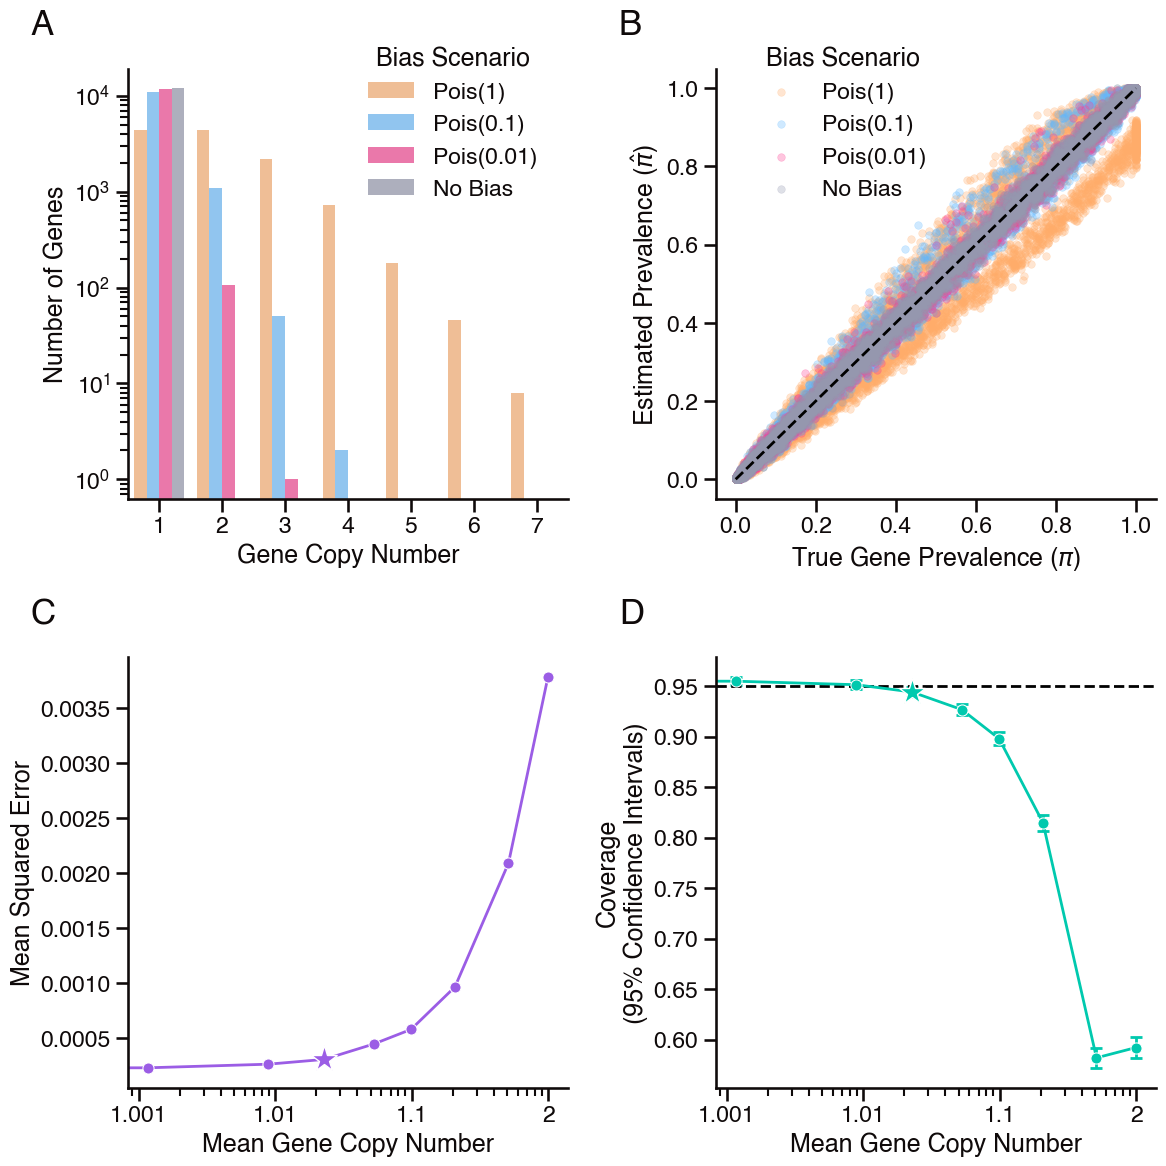

In [12]:
# build multi-panel figure showing results from copy number experiment

# build figure with 2 rows and 2 columns of subplots
fig, axes = plt.subplots(2, 2, figsize=(12, 12))

# build plot A: overlay of gene detection bias distributions for different mean copy numbers
subset = ['Pois(1)', 'Pois(0.1)', 'Pois(0.01)', 'No Bias']
color_mapping = dict(zip(subset, [palette[i] for i in [1, 7, 3, 5][:len(subset)]]))
subset_df = counts_df[subset].melt(
    var_name='label', value_name='gene_count').groupby(
        'label')['gene_count'].value_counts().reset_index()
subset_df['gene_count'] = subset_df['gene_count'].astype(int)
sns.barplot(
    data=subset_df,
    x='gene_count',
    y='count',
    hue='label',
    hue_order=subset,
    palette=color_mapping,
    alpha=0.8,
    ax=axes[0, 0]
)
axes[0, 0].set_xlabel("Gene Copy Number")
axes[0, 0].set_ylabel("Number of Genes")
axes[0, 0].set_yscale('log')
axes[0, 0].legend(title="Bias Scenario", bbox_to_anchor=(0.5, 1.1), loc='upper left')
axes[0, 0].annotate("A", **annotation_kwargs)

# plot B: scatterplots of true pi values vs. estimated pi values for each beta distribution parameter
for i, label in enumerate(subset):
    sns.scatterplot(
        x=pi_predictions_df['true_pi'], 
        y=pi_predictions_df[label], 
        label=label,
        color=color_mapping[label], 
        alpha=0.3, 
        s=30, 
        edgecolor=None,
        ax=axes[0, 1]
    )
# add diagonal line for reference
axes[0, 1].plot([0, 1], [0, 1], color='black', linestyle='--', zorder=1)
axes[0, 1].set_xlabel(r"True Gene Prevalence ($\pi$)")
axes[0, 1].set_ylabel(r"Estimated Prevalence ($\hat{\pi}$)")
axes[0, 1].legend(title="Bias Scenario", bbox_to_anchor=(0.05, 1.1), loc='upper left')
axes[0, 1].annotate("B", **annotation_kwargs)

# plot C: MSE of estimated pi values compared to true pi values for each beta distribution parameter (overall category)
overall_cn_df = cn_test_df[cn_test_df['category'] == 'overall']
sns.lineplot(
    data=overall_cn_df, 
    x='mean_cn_minus_one', 
    y='mse', 
    color=palette[0], 
    ax=axes[1, 0], 
    marker='o', 
    ms=8
)
axes[1, 0].set_xlabel("Mean Gene Copy Number")
axes[1, 0].set_xscale('log')
axes[1, 0].set_ylabel("Mean Squared Error")
# change x-tick labels to reflect copy number
axes[1, 0].set_xticks([0.001, 0.01, 0.1, 1])
axes[1, 0].set_xticklabels(['1.001', '1.01', '1.1', '2'])
# mark the MSE for Pois(0.023) with a star
mse_0023 = overall_cn_df[overall_cn_df['label'] == 'Pois(0.023)']['mse'].values[0]
mean_cn_minus_one_0023 = overall_cn_df[overall_cn_df['label'] == 'Pois(0.023)']['mean_cn_minus_one'].values[0]
axes[1, 0].plot(mean_cn_minus_one_0023, mse_0023, marker='*', color=palette[0], markersize=20, markeredgecolor='white')
# annotation for subplot C
axes[1, 0].annotate("C", **annotation_kwargs)

# plot D: coverage of confidence intervals for each beta distribution parameter (overall category)
sns.lineplot(
    data=overall_cn_df, 
    x='mean_cn_minus_one',
    y='coverage', 
    color=palette[2], 
    ax=axes[1, 1], 
    marker='o', 
    ms=8
)
# add error bars for +/- 2 standard errors of the coverage estimate
axes[1, 1].errorbar(
    x=overall_cn_df['mean_cn_minus_one'],
    y=overall_cn_df['coverage'],
    yerr=(overall_cn_df['se_coverage'] * 2),  # 2 standard errors for approximate 95% confidence interval
    fmt='none',
    ecolor=palette[2],
    elinewidth=2,
    capsize=4,
    capthick=2, 
    zorder=0
)
axes[1, 1].set_xlabel("Mean Gene Copy Number")
axes[1, 1].set_xscale('log')
axes[1, 1].set_ylabel(f"Coverage\n({(1 - ci_alpha):.0%} Confidence Intervals)")
axes[1, 1].axhline(1 - ci_alpha, color='black', linestyle='--', zorder=1)
# change x-tick labels to reflect copy number
axes[1, 1].set_xticks([0.001, 0.01, 0.1, 1])
axes[1, 1].set_xticklabels(['1.001', '1.01', '1.1', '2'])
# mark the coverage for Pois(0.023) with a star
coverage_0023 = overall_cn_df[overall_cn_df['label'] == 'Pois(0.023)']['coverage'].values[0]
axes[1, 1].plot(mean_cn_minus_one_0023, coverage_0023, marker='*', color=palette[2], markersize=20, markeredgecolor='white')
# annotation for subplot D
axes[1, 1].annotate("D", **annotation_kwargs)   

# show and save the figure
plt.tight_layout()
# plt.savefig("bias_simulation_results.png", dpi=300, bbox_inches='tight')
plt.show()


## Main text figure
Build multipanel figure that combines results from two of these experiments to be used as a main-text figure.

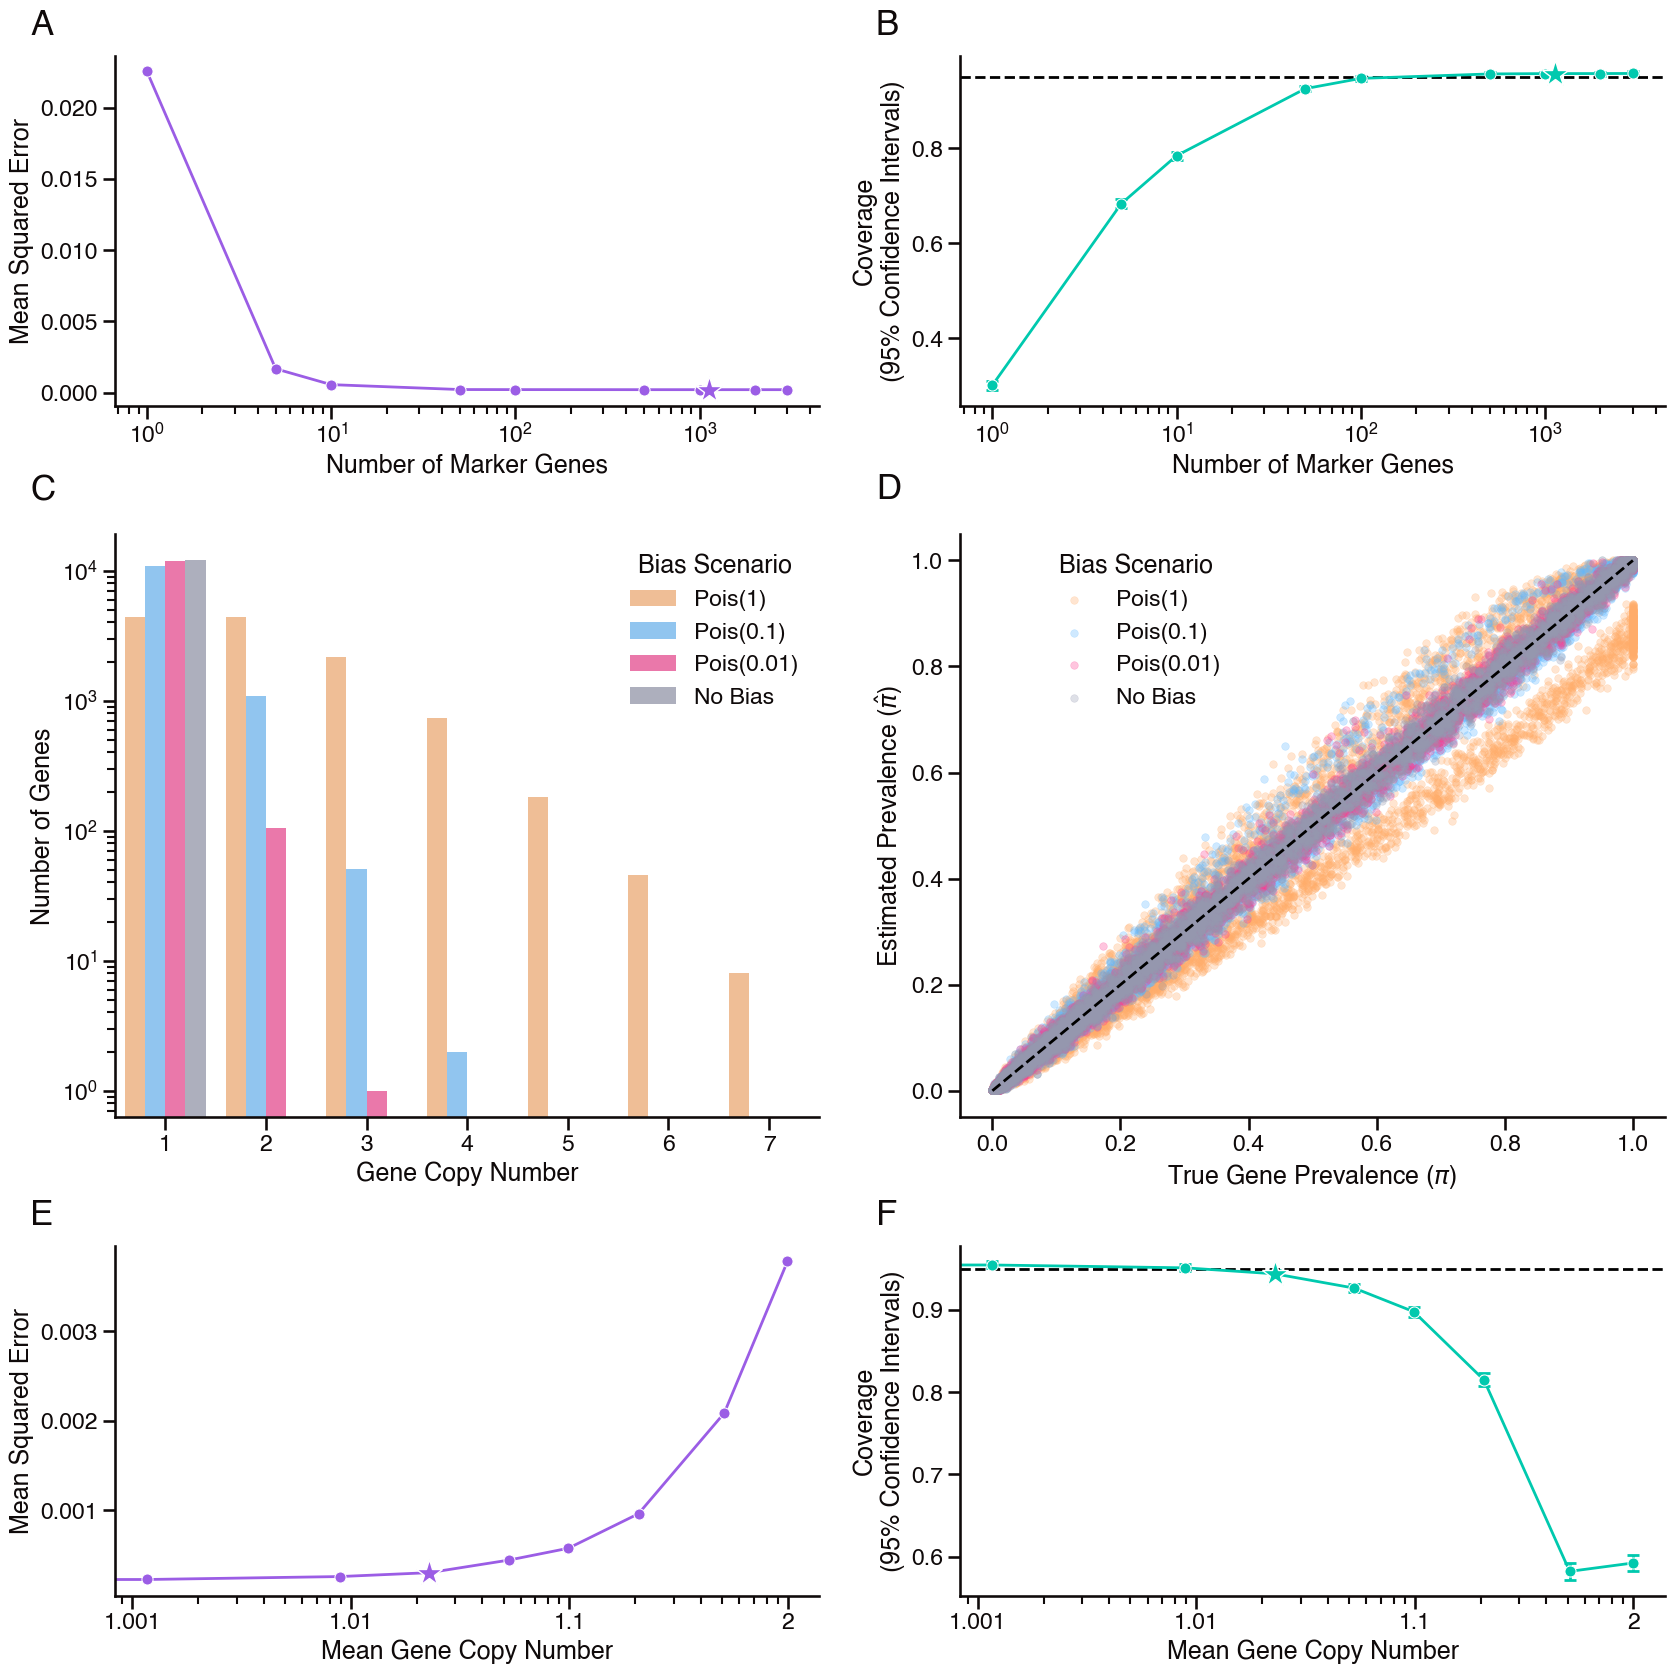

In [20]:
# build six-panel compound figure that combines the results from the completeness bias simulations 
# and the copy number bias simulations, with shared legends for the bias scenarios and consistent color schemes across all panels

# build compound figure with 3 rows and 2 columns
fig = plt.figure(figsize=(20, 20))
gs = fig.add_gridspec(3, 2, height_ratios=[0.6, 1, 0.6], hspace=0.3, wspace=0.2)

# annotation specs
annotation_kwargs = dict(
    xy=(-0.12, 1.06),
    xycoords='axes fraction',
    fontsize=25,
    fontweight='bold'
)

# plot A: MSE as a function of number of marker genes (completeness misestimation scenario)
ax1 = fig.add_subplot(gs[0, 0])
sns.lineplot(
    data=overall_df, 
    x='n_marker_genes', 
    y='mse', 
    color=palette[0],
    marker='o', 
    ms=8, 
    ax=ax1
)
ax1.set_xscale('log')
ax1.set_xlabel('Number of Marker Genes')
ax1.set_ylabel('Mean Squared Error')
# mark the MSE for 1128 marker genes with a star
mse_1128 = overall_df[overall_df['n_marker_genes'] == 1128]['mse'].values[0]
ax1.plot(1128, mse_1128, marker='*', color=palette[0], markersize=20, markeredgecolor='white')
# add annotation for subplot A
ax1.annotate("A", **annotation_kwargs)

# plot B: coverage as a function of number of marker genes
ax2 = fig.add_subplot(gs[0, 1])
sns.lineplot(
    data=overall_df, 
    x='n_marker_genes', 
    y='coverage', 
    color=palette[2],
    marker='o', 
    ms=8,
    ax=ax2
)
# add error bars for +/- 2 standard errors of the coverage estimate
ax2.errorbar(
    x=overall_df['n_marker_genes'],
    y=overall_df['coverage'],
    yerr=(overall_df['se_coverage'] * 2),  # 2 standard errors for approximate 95% confidence interval
    fmt='none',
    ecolor=palette[2],
    elinewidth=2,
    capsize=4,
    capthick=2, 
    zorder=0
)
ax2.set_xscale('log')
ax2.set_xlabel('Number of Marker Genes')
ax2.set_ylabel(f'Coverage\n({(1 - ci_alpha):.0%} Confidence Intervals)')
# add horizontal line at the nominal coverage level as reference
ax2.axhline(1 - ci_alpha, color='black', linestyle='--', zorder=1)
# mark the coverage for 1128 marker genes with a star
coverage_1128 = overall_df[overall_df['n_marker_genes'] == 1128]['coverage'].values[0]
ax2.plot(1128, coverage_1128, marker='*', color=palette[2], markersize=20, markeredgecolor='white')
# add annotation for subplot B
ax2.annotate("B", **annotation_kwargs)

# build plot C: overlay of gene detection bias distributions for different mean copy numbers
ax3 = fig.add_subplot(gs[1, 0])
sns.barplot(
    data=subset_df,
    x='gene_count',
    y='count',
    hue='label',
    hue_order=subset,
    palette=color_mapping,
    alpha=0.8,
    ax=ax3
)
ax3.set_xlabel("Gene Copy Number")
ax3.set_ylabel("Number of Genes")
ax3.set_yscale('log')
ax3.legend(title="Bias Scenario")
# ax3.legend(title="Bias Scenario", bbox_to_anchor=(0.1, 1), loc='upper left')
ax3.annotate("C", **annotation_kwargs)

# plot D: scatterplots of true pi values vs. estimated pi values for each beta distribution parameter
ax4 = fig.add_subplot(gs[1, 1])
for i, label in enumerate(subset):
    sns.scatterplot(
        x=pi_predictions_df['true_pi'], 
        y=pi_predictions_df[label], 
        label=label,
        color=color_mapping[label], 
        alpha=0.3, 
        s=30, 
        edgecolor=None,
        ax=ax4
    )
# add diagonal line for reference
ax4.plot([0, 1], [0, 1], color='black', linestyle='--', zorder=1)
ax4.set_xlabel(r"True Gene Prevalence ($\pi$)")
ax4.set_ylabel(r"Estimated Prevalence ($\hat{\pi}$)")
ax4.legend(title="Bias Scenario", bbox_to_anchor=(0.1, 1), loc='upper left')
# ax4.legend(title="Bias Scenario")
ax4.annotate("D", **annotation_kwargs)

# plot E: MSE of estimated pi values compared to true pi values for each beta distribution parameter (overall category)
ax5 = fig.add_subplot(gs[2, 0])
sns.lineplot(
    data=overall_cn_df, 
    x='mean_cn_minus_one', 
    y='mse', 
    color=palette[0], 
    ax=ax5, 
    marker='o', 
    ms=8
)
ax5.set_xlabel("Mean Gene Copy Number")
ax5.set_xscale('log')
ax5.set_ylabel("Mean Squared Error")
# change x-tick labels to reflect copy number
ax5.set_xticks([0.001, 0.01, 0.1, 1])
ax5.set_xticklabels(['1.001', '1.01', '1.1', '2'])
# mark the MSE for Pois(0.023) with a star
mse_0023 = overall_cn_df[overall_cn_df['label'] == 'Pois(0.023)']['mse'].values[0]
mean_cn_minus_one_0023 = overall_cn_df[overall_cn_df['label'] == 'Pois(0.023)']['mean_cn_minus_one'].values[0]
ax5.plot(mean_cn_minus_one_0023, mse_0023, marker='*', color=palette[0], markersize=20, markeredgecolor='white')
# annotation for subplot C
ax5.annotate("E", **annotation_kwargs)

# plot F: coverage of confidence intervals for each beta distribution parameter (overall category)
ax6 = fig.add_subplot(gs[2, 1])
sns.lineplot(
    data=overall_cn_df, 
    x='mean_cn_minus_one',
    y='coverage', 
    color=palette[2], 
    ax=ax6, 
    marker='o', 
    ms=8
)
# add error bars for +/- 2 standard errors of the coverage estimate
ax6.errorbar(
    x=overall_cn_df['mean_cn_minus_one'],
    y=overall_cn_df['coverage'],
    yerr=(overall_cn_df['se_coverage'] * 2),  # 2 standard errors for approximate 95% confidence interval
    fmt='none',
    ecolor=palette[2],
    elinewidth=2,
    capsize=4,
    capthick=2, 
    zorder=0
)
ax6.set_xlabel("Mean Gene Copy Number")
ax6.set_xscale('log')
ax6.set_ylabel(f"Coverage\n({(1 - ci_alpha):.0%} Confidence Intervals)")
ax6.axhline(1 - ci_alpha, color='black', linestyle='--', zorder=1)
# change x-tick labels to reflect copy number
ax6.set_xticks([0.001, 0.01, 0.1, 1])
ax6.set_xticklabels(['1.001', '1.01', '1.1', '2'])
# mark the coverage for Pois(0.023) with a star
coverage_0023 = overall_cn_df[overall_cn_df['label'] == 'Pois(0.023)']['coverage'].values[0]
ax6.plot(mean_cn_minus_one_0023, coverage_0023, marker='*', color=palette[2], markersize=20, markeredgecolor='white')
# annotation for subplot F
ax6.annotate("F", **annotation_kwargs)

# show and save the figure
# plt.savefig("model-robustness-experiments.png", dpi=300, bbox_inches='tight')
plt.show()